# Notebook 1: Background removal (masks for pipelines R1 to R9)

This notebook makes a **second version of every image with the background erased**. It runs **once**. Nothing is trained here.

```
Stage 0 image                         Output of this notebook
[weapon on grass / table / shop]  ->  [same weapon on plain gray, same size and framing]
```

**Input:** the saved output of your Stage 0 notebook (it contains `stage0/metadata/manifest.csv` and `stage0/standardized/`).

**Output (in `/kaggle/working/bg_removed/`):**

| Path | Contents |
|---|---|
| `cutouts/<image_id>.png` | weapon on plain gray background, same size as the Stage 0 image (used by R1 to R9) |
| `masks/<image_id>.png` | the mask itself (white = weapon, black = background) |
| `mask_manifest.csv` | Stage 0 manifest plus `cutout_path`, `mask_path`, `mask_status`, `fg_frac` |
| `figures/` | before/after sheets for checking the masks by eye |

**How masks are made:** the `rembg` tool with the `isnet-general-use` model predicts a soft mask. The mask is then cleaned: tiny holes are filled, stray specks are removed, soft edges are kept so thin blade tips survive. Real holes (for example the ring of a scissor handle) are kept open. Images where removal fails (almost nothing or almost everything detected) keep their original image and are marked in `mask_status`, so no image is lost.

**Kaggle settings:** Internet **On**. Accelerator can be **None** (CPU); about 30 to 40 minutes for 1,100 images. The notebook can be re-run: images already done are skipped. Always start from a fresh session (if an earlier install changed packages, restart the session first).

## 1. Install

Installs `rembg` **without** letting it upgrade Kaggle's own packages (numpy, pillow, scikit-image). Only the missing pieces are added: the `onnxruntime` engine and three small helpers.

In [1]:
import importlib.metadata, subprocess, sys

def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

def installed(package):
    try:
        importlib.metadata.version(package)
        return True
    except importlib.metadata.PackageNotFoundError:
        return False

# 1) the engine rembg runs on, plus small helpers (existing numpy / pillow are not touched)
for package in ["onnxruntime", "pymatting", "pooch", "jsonschema"]:
    if not installed(package):
        pip_install(package)

# 2) rembg itself, WITHOUT dependencies, so Kaggle's numpy / pillow / scikit-image stay as they are
if not installed("rembg"):
    pip_install("--no-deps", "rembg")

import numpy, PIL, onnxruntime, rembg
print("numpy", numpy.__version__, "| pillow", PIL.__version__, "| onnxruntime", onnxruntime.__version__, "| rembg ready")

numpy 2.1.3 | pillow 13.0.0 | onnxruntime 1.31.0 | rembg ready


## 2. Configuration

In [2]:
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").is_dir()

if ON_KAGGLE:
    INPUT_SEARCH_ROOT = Path("/kaggle/input")               # Stage 0 output is found automatically
    OUT_ROOT          = Path("/kaggle/working/bg_removed")
else:
    INPUT_SEARCH_ROOT = Path(r"H:\BD Weapon Stage0")        # local alternative
    OUT_ROOT          = Path(r"H:\BD Weapon BG Removed")

MODEL_NAME         = "isnet-general-use"  # good general-object model; "u2net" is faster, "birefnet-general" is sharper but much slower on CPU
BG_GRAY            = (128, 128, 128)      # plain background colour for the cut-outs
MASK_THRESHOLD     = 0.5                  # soft-mask value above which a pixel counts as weapon (for cleaning and statistics)
MIN_COMPONENT_FRAC = 0.05                 # remove blobs smaller than 5% of the largest blob (keeps several weapons in one photo)
MAX_HOLE_FRAC      = 0.001                # fill holes smaller than 0.1% of the image; larger holes (handle rings) stay open
FAIL_MIN_FG        = 0.005                # mask covering < 0.5% of the image  -> removal failed
FAIL_MAX_FG        = 0.95                 # mask covering > 95% of the image   -> removal failed
N_CHECK_SAMPLES    = 48                   # random before/after pairs saved for visual checking
SEED               = 42

In [3]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from rembg import new_session, remove

def find_stage0_root(base):
    # walk the input folders (following links) until stage0/metadata/manifest.csv is found
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        d = Path(dirpath)
        if "manifest.csv" in filenames and d.name == "metadata" and d.parent.name == "stage0":
            return d.parent
        dirnames[:] = [x for x in dirnames if x not in ("standardized", "figures", "cutouts", "masks")]
    return None

STAGE0 = find_stage0_root(INPUT_SEARCH_ROOT)
assert STAGE0 is not None, (f"No stage0/metadata/manifest.csv found under {INPUT_SEARCH_ROOT}. "
                            "Attach the saved output of your Stage 0 notebook with Add Input.")
manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
print("Stage 0 output:", STAGE0)
print("Images in manifest:", len(manifest))
display(manifest.label.value_counts().to_frame("images").T)

CUT_DIR, MASK_DIR, FIG_DIR = OUT_ROOT / "cutouts", OUT_ROOT / "masks", OUT_ROOT / "figures"
for d in (CUT_DIR, MASK_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

Stage 0 output: /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
Images in manifest: 2950


label,Dao,Churi,Kodal,Kural,Shabol,Khor
images,530,521,477,477,474,471


## 3. Mask cleaning and compositing

In [4]:
def clean_mask(alpha):
    # alpha: uint8 soft mask (0-255). Returns (clean soft alpha uint8, binary mask bool, n_components).
    h, w = alpha.shape
    binm = alpha >= int(MASK_THRESHOLD * 255)

    # close tiny gaps along the object
    k = max(3, int(round(min(h, w) * 0.005)) | 1)
    binm = cv2.morphologyEx(binm.astype(np.uint8), cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))).astype(bool)

    # fill only SMALL holes (segmentation errors); large holes such as handle rings stay open
    n_bg, bg_lab, bg_stats, _ = cv2.connectedComponentsWithStats((~binm).astype(np.uint8), connectivity=4)
    border = set(np.unique(np.concatenate([bg_lab[0], bg_lab[-1], bg_lab[:, 0], bg_lab[:, -1]])))
    for lab in range(1, n_bg):
        if lab not in border and bg_stats[lab, cv2.CC_STAT_AREA] < MAX_HOLE_FRAC * h * w:
            binm[bg_lab == lab] = True

    # drop specks: keep blobs >= MIN_COMPONENT_FRAC of the largest blob
    n_fg, fg_lab, fg_stats, _ = cv2.connectedComponentsWithStats(binm.astype(np.uint8), connectivity=8)
    if n_fg > 1:
        areas = fg_stats[1:, cv2.CC_STAT_AREA]
        keep = [i + 1 for i, a in enumerate(areas) if a >= MIN_COMPONENT_FRAC * areas.max()]
        binm = np.isin(fg_lab, keep)
        n_comp = len(keep)
    else:
        n_comp = 0

    # soft alpha: keep the model's soft edges near the object, fully opaque inside the cleaned mask
    zone = cv2.dilate(binm.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))).astype(bool)
    soft = np.where(zone, alpha, 0).astype(np.uint8)
    soft[binm] = 255
    return soft, binm, n_comp

def composite(rgb, soft_alpha):
    a = (soft_alpha.astype(np.float32) / 255.0)[..., None]
    bg = np.array(BG_GRAY, dtype=np.float32)[None, None, :]
    return np.clip(rgb.astype(np.float32) * a + bg * (1 - a) + 0.5, 0, 255).astype(np.uint8)

## 4. Run background removal

Skips images that already have a cut-out, so the cell can be re-run after an interruption.

In [5]:
session = new_session(MODEL_NAME)
STATUS_CACHE = OUT_ROOT / "mask_status_cache.csv"
cache = pd.read_csv(STATUS_CACHE, dtype={"image_id": str}).set_index("image_id") if STATUS_CACHE.exists() else None

records = []
for r in tqdm(manifest.itertuples(index=False), total=len(manifest), desc="removing background"):
    cut_p, mask_p = CUT_DIR / f"{r.image_id}.png", MASK_DIR / f"{r.image_id}.png"
    if cache is not None and r.image_id in cache.index and cut_p.exists() and mask_p.exists():
        records.append(cache.loc[r.image_id].to_dict() | {"image_id": r.image_id})
        continue
    rgb = np.asarray(Image.open(STAGE0 / r.path).convert("RGB"))
    alpha = np.asarray(remove(Image.fromarray(rgb), session=session, only_mask=True).convert("L"))
    if alpha.shape != rgb.shape[:2]:
        alpha = cv2.resize(alpha, (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_LINEAR)
    soft, binm, n_comp = clean_mask(alpha)
    fg = float(binm.mean())
    if fg < FAIL_MIN_FG:
        status = "failed_empty"
    elif fg > FAIL_MAX_FG:
        status = "failed_full"
    else:
        status = "ok"
    if status == "ok":
        out = composite(rgb, soft)
    else:
        out = rgb                      # fallback: keep the original image so nothing is lost
        soft = np.full(rgb.shape[:2], 255, np.uint8)
    Image.fromarray(out).save(cut_p)
    Image.fromarray(soft).save(mask_p)
    records.append({"image_id": r.image_id, "mask_status": status, "fg_frac": round(fg, 5),
                    "n_components": n_comp})
    if len(records) % 50 == 0:
        pd.DataFrame(records).to_csv(STATUS_CACHE, index=False)

status_df = pd.DataFrame(records)
status_df.to_csv(STATUS_CACHE, index=False)
print(status_df.mask_status.value_counts().to_string())

  0%|                                               | 0.00/179M [00:00<?, ?B/s]

removing background:   0%|          | 0/2950 [00:00<?, ?it/s]

mask_status
ok              2856
failed_empty      94


## 5. Save the mask manifest and summary

In [6]:
mm = manifest.merge(status_df, on="image_id", how="left")
mm["cutout_path"] = "cutouts/" + mm.image_id + ".png"
mm["mask_path"] = "masks/" + mm.image_id + ".png"
mm.to_csv(OUT_ROOT / "mask_manifest.csv", index=False)

summary = mm.groupby("label").agg(images=("image_id", "size"),
                                  ok=("mask_status", lambda s: int((s == "ok").sum())),
                                  failed=("mask_status", lambda s: int((s != "ok").sum())),
                                  median_fg_frac=("fg_frac", "median")).round(3)
display(summary)
n_fail = int((mm.mask_status != "ok").sum())
print(f"Background removed for {len(mm) - n_fail} of {len(mm)} images; {n_fail} kept their original image (fallback).")
_ = (OUT_ROOT / "bg_removal_report.json").write_text(json.dumps({
    "model": MODEL_NAME, "images": int(len(mm)), "failed_fallback_to_original": n_fail,
    "status_counts": {k: int(v) for k, v in mm.mask_status.value_counts().items()},
    "settings": {"MASK_THRESHOLD": MASK_THRESHOLD, "MIN_COMPONENT_FRAC": MIN_COMPONENT_FRAC,
                 "MAX_HOLE_FRAC": MAX_HOLE_FRAC, "BG_GRAY": BG_GRAY},
}, indent=2))

,images,ok,failed,median_fg_frac
label,,,,
Churi,521,519,2,0.099
Dao,530,525,5,0.103
Khor,471,471,0,0.071
Kodal,477,455,22,0.067
Kural,477,457,20,0.070
Shabol,474,429,45,0.042


Background removed for 2856 of 2950 images; 94 kept their original image (fallback).


## 6. Visual check

Before/after pairs: a random sample from every class, and every image where removal failed. Look for blade tips that were cut off, handles that disappeared, or background left behind.

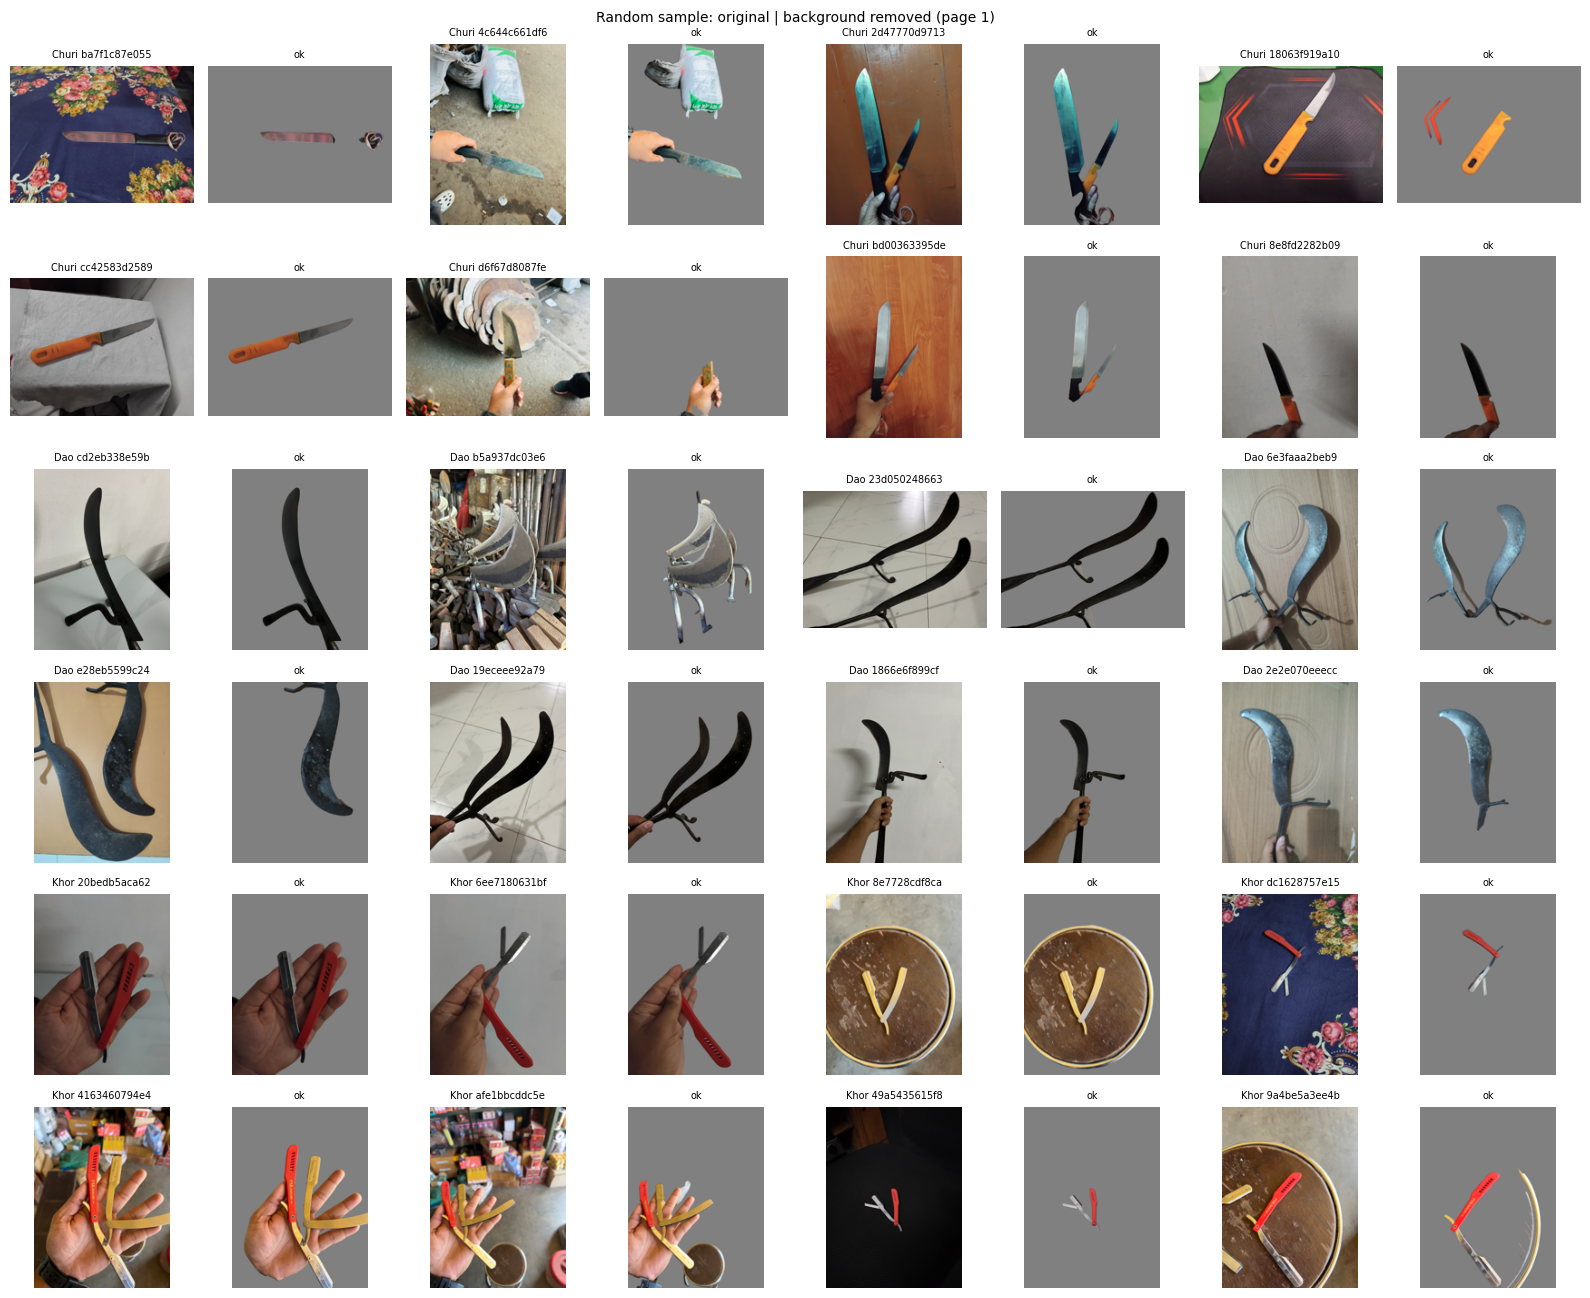

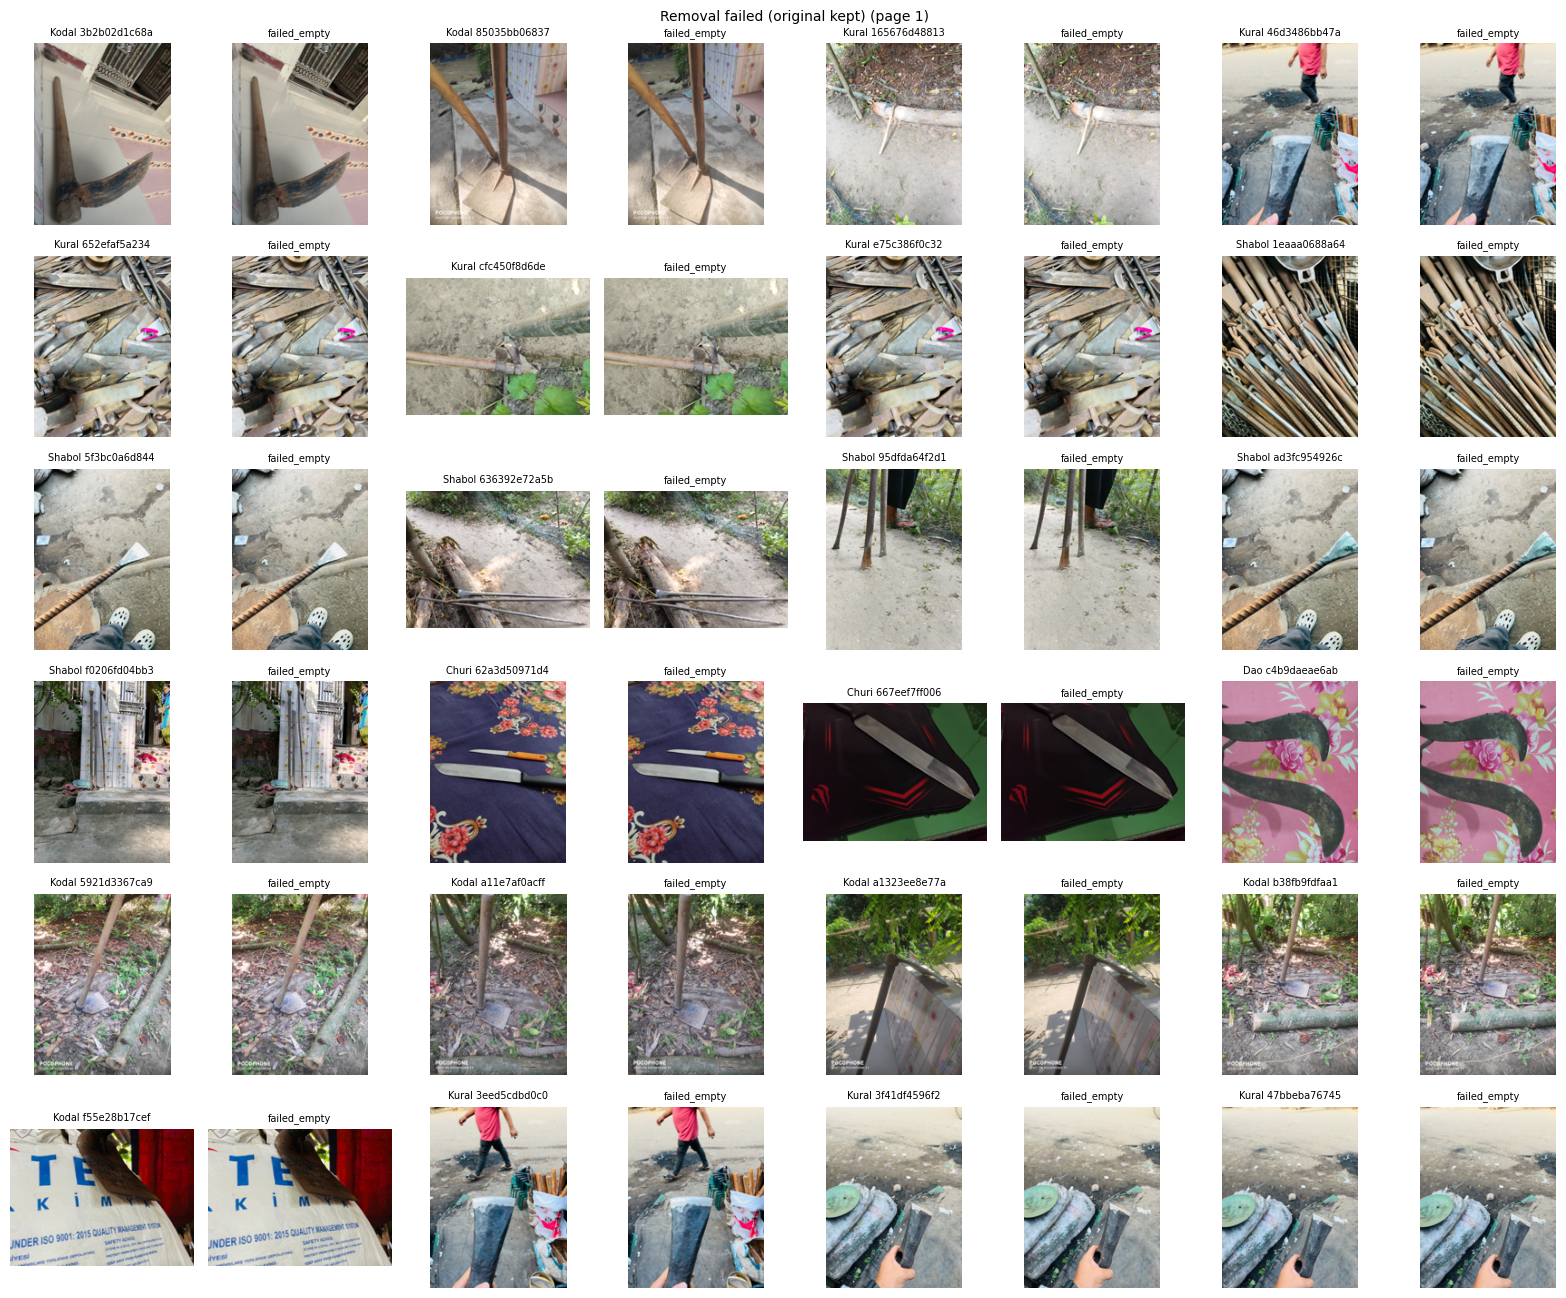

Sheets saved in /kaggle/working/bg_removed/figures


In [7]:
def pair_sheet(ids, out_name, title, per_page=24, thumb=200):
    ids = list(ids)
    for p in range(0, max(len(ids), 1), per_page):
        chunk = ids[p:p + per_page]
        if not chunk:
            break
        rows = int(np.ceil(len(chunk) / 4))
        fig, axes = plt.subplots(rows, 8, figsize=(16, rows * 2.2), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        info = mm.set_index("image_id")
        for k, iid in enumerate(chunk):
            r, c = divmod(k, 4)
            for j, path in enumerate([STAGE0 / info.loc[iid, "path"], OUT_ROOT / info.loc[iid, "cutout_path"]]):
                with Image.open(path) as im:
                    im.thumbnail((thumb, thumb))
                    axes[r, 2 * c + j].imshow(np.asarray(im.convert("RGB")))
            axes[r, 2 * c].set_title(f"{info.loc[iid, 'label']} {iid}", fontsize=7)
            axes[r, 2 * c + 1].set_title(info.loc[iid, "mask_status"], fontsize=7)
        fig.suptitle(f"{title} (page {p // per_page + 1})", fontsize=10)
        fig.tight_layout()
        fig.savefig(FIG_DIR / f"{out_name}_p{p // per_page + 1:02d}.png", dpi=100)
        if p == 0:
            plt.show()
        plt.close(fig)

rng = np.random.default_rng(SEED)
per_class = max(1, N_CHECK_SAMPLES // mm.label.nunique())
sample_ids = [i for _, g in mm.groupby("label")
              for i in rng.choice(g.image_id, size=min(per_class, len(g)), replace=False)]
pair_sheet(sample_ids, "check_random", "Random sample: original | background removed")
failed_ids = mm.image_id[mm.mask_status != "ok"]
if len(failed_ids):
    pair_sheet(failed_ids, "check_failed", "Removal failed (original kept)")
print("Sheets saved in", FIG_DIR)

## 7. Finish

1. Look at the sheets above (and in `bg_removed/figures/`). A few imperfect masks are normal; the same automatic tool is used for every image, so the comparison stays fair.
2. Click **Save Version, Save & Run All (Commit)**. The cut-outs are then stored permanently.
3. Notebook 2 (training) attaches this notebook's output together with the Stage 0 output. The R pipelines read `bg_removed/mask_manifest.csv` and the `cutouts/` folder.

For the paper: report the model (`isnet-general-use` via rembg), the cleaning steps, and how many images fell back to the original.